Lab — From Text to BERT
Name: Anant Arya
Roll number: A24ARIU0014

All 11 exercises are implemented with short comments and checks. Open in Colab or Kaggle and run cells in order. Parts A1–A2 and B use no downloaded data; later parts download WikiText, tokenizers, and BERT. Enable internet and preferably a GPU. The BERT weights are approximately 440 MB. This lab uses pretrained weights for inference; it does not train BERT.

Numerical results, attention matrices, and output-dependent answers are calculated when run. This notebook does not contain precomputed model results.

In [1]:
import sys, subprocess, importlib.util, collections, math, random
for package in ("transformers", "tokenizers", "datasets", "matplotlib"):
    if importlib.util.find_spec(package) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])
import torch
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
SEED = 42
random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| device:", device)
MLM_PARAGRAPHS = 512
MLM_BATCH_SIZE = 8 if device.type == "cuda" else 2

PyTorch: 2.11.0+cpu | device: cpu


Part A — Exercises 1 and 2: BPE and WordPiece

In [2]:
TOY_BASE_VOCAB = set("bghnpsu")
TOY_MERGES = [(("u", "g"), "ug"), (("u", "n"), "un"), (("h", "ug"), "hug")]

def bpe_tokenize_word(word, merges, base_vocab, unk_token="[UNK]"):
    pieces = [char if char in base_vocab else unk_token for char in word]
    for (a, b), merged in merges:
        result, i = [], 0
        while i < len(pieces):
            if i + 1 < len(pieces) and pieces[i] == a and pieces[i+1] == b:
                result.append(merged); i += 2
            else:
                result.append(pieces[i]); i += 1
        pieces = result
    return pieces

TOY_WP_VOCAB = {"[UNK]", "b", "h", "p", "u", "##u", "##g", "##n", "##s", "hu", "hug", "##gs", "##un"}

def wordpiece_tokenize_word(word, vocab, unk_token="[UNK]", prefix="##"):
    pieces, start = [], 0
    while start < len(word):
        match = None
        for end in range(len(word), start, -1):
            piece = word[start:end]
            if start > 0: piece = prefix + piece
            if piece in vocab:
                match = piece
                break
        if match is None: return [unk_token]
        pieces.append(match)
        start = end
    return pieces

bpe_cases = {"hugs":["hug","s"], "bug":["b","ug"], "pun":["p","un"],
             "mug":["[UNK]","ug"], "thug":["[UNK]","hug"], "unhug":["un","hug"]}
wp_cases = {"hugs":["hug","##s"], "bun":["b","##un"], "pugs":["p","##u","##gs"],
            "hu":["hu"], "mug":["[UNK]"], "hugsx":["[UNK]"]}
for word, expected in bpe_cases.items():
    actual = bpe_tokenize_word(word, TOY_MERGES, TOY_BASE_VOCAB)
    assert actual == expected
    print("BPE", word, actual)
for word, expected in wp_cases.items():
    actual = wordpiece_tokenize_word(word, TOY_WP_VOCAB)
    assert actual == expected
    print("WordPiece", word, actual)
print("Exercises 1 and 2 checks passed")

BPE hugs ['hug', 's']
BPE bug ['b', 'ug']
BPE pun ['p', 'un']
BPE mug ['[UNK]', 'ug']
BPE thug ['[UNK]', 'hug']
BPE unhug ['un', 'hug']
WordPiece hugs ['hug', '##s']
WordPiece bun ['b', '##un']
WordPiece pugs ['p', '##u', '##gs']
WordPiece hu ['hu']
WordPiece mug ['[UNK]']
WordPiece hugsx ['[UNK]']
Exercises 1 and 2 checks passed


Answer 1. Adding h + u → hu first makes hug become ['hu', 'g']. The later u + g and h + ug rules no longer match. Earlier merges change which adjacent units remain, so their learned order matters.

Answer 2. Character-based toy BPE preserves recognized fragments around an unknown character. Whole-word [UNK] in this WordPiece exercise avoids retaining a misleading incomplete segmentation, but loses recognized fragments. GPT-2 starts from a complete set of byte symbols, so every UTF-8 input can be represented without an unknown token.

Part B — Exercises 5–7: masked attention and its matrix
This independent section runs before the downloads so the attention implementation can be checked first.

Exercises 5 and 6 checks passed
Attention matrix (sample 2, head 1):
 [[0.645 0.173 0.182 0.    0.   ]
 [0.794 0.155 0.052 0.    0.   ]
 [0.15  0.377 0.472 0.    0.   ]
 [0.072 0.346 0.582 0.    0.   ]
 [0.306 0.419 0.276 0.    0.   ]]


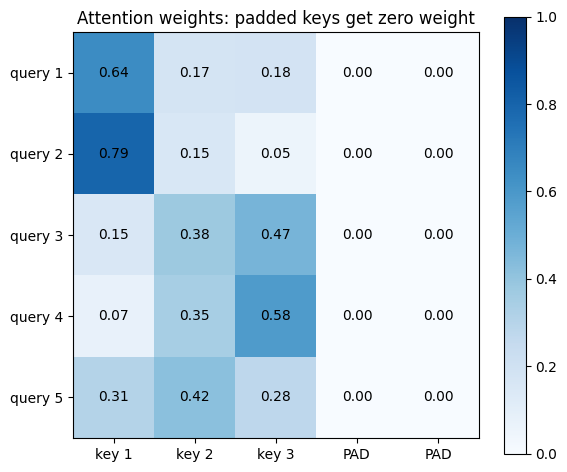

In [3]:
def scaled_dot_product_attention(q, k, v, mask=None):
    scores = q @ k.transpose(-2, -1) / math.sqrt(q.size(-1))
    if mask is not None: scores = scores.masked_fill(~mask, float("-inf"))
    weights = torch.softmax(scores, dim=-1)
    return weights @ v, weights

def make_padding_mask(input_ids, pad_id):
    return input_ids.ne(pad_id)[:, None, None, :]

g = torch.Generator().manual_seed(0)
B, H, T, d_k = 2, 3, 5, 4
q, k, v = (torch.randn(B,H,T,d_k,generator=g) for _ in range(3))
lengths = torch.tensor([5,3])
mask = (torch.arange(T)[None,:] < lengths[:,None])[:,None,None,:]
out, weights = scaled_dot_product_attention(q,k,v,mask)
assert out.shape == (B,H,T,d_k) and weights.shape == (B,H,T,T)
assert torch.allclose(weights.sum(-1), torch.ones(B,H,T))
assert (weights[1,:,:,3:] == 0).all()
assert torch.allclose(out, F.scaled_dot_product_attention(q,k,v,attn_mask=mask), atol=1e-5)
assert torch.allclose(scaled_dot_product_attention(q,k,v)[0], F.scaled_dot_product_attention(q,k,v), atol=1e-5)
ids = torch.tensor([[5,6,7,0,0],[8,9,10,11,12]])
assert make_padding_mask(ids,0).shape == (2,1,1,5)
assert make_padding_mask(ids,0).dtype == torch.bool
assert make_padding_mask(ids,0)[0,0,0].tolist() == [True,True,True,False,False]
print("Exercises 5 and 6 checks passed")

# Display one head's matrix for the sequence with two padded key positions.
matrix = weights[1,0].numpy()
print("Attention matrix (sample 2, head 1):\n", matrix.round(3))
fig, ax = plt.subplots(figsize=(6,5))
im = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1)
for r in range(T):
    for c in range(T): ax.text(c,r,f"{matrix[r,c]:.2f}",ha="center",va="center")
ax.set_xticks(range(T), ["key 1","key 2","key 3","PAD","PAD"])
ax.set_yticks(range(T), [f"query {i+1}" for i in range(T)])
ax.set_title("Attention weights: padded keys get zero weight")
fig.colorbar(im,ax=ax); plt.tight_layout(); plt.show()

In [4]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        assert d_model % n_heads == 0
        self.h, self.d_k = n_heads, d_model // n_heads
        self.W_q, self.W_k, self.W_v, self.W_o = (nn.Linear(d_model,d_model) for _ in range(4))
    def forward(self,x,mask=None):
        B,T,D = x.shape
        def split(t): return t.view(B,T,self.h,self.d_k).transpose(1,2)
        out,w = scaled_dot_product_attention(split(self.W_q(x)),split(self.W_k(x)),split(self.W_v(x)),mask)
        return self.W_o(out.transpose(1,2).reshape(B,T,D)),w

class EncoderLayer(nn.Module):
    def __init__(self,d_model,n_heads,d_ff,dropout=0.1):
        super().__init__()
        self.attn = MultiHeadSelfAttention(d_model,n_heads)
        self.ff = nn.Sequential(nn.Linear(d_model,d_ff),nn.ReLU(),nn.Linear(d_ff,d_model))
        self.norm1,self.norm2 = nn.LayerNorm(d_model),nn.LayerNorm(d_model)
        self.drop = nn.Dropout(dropout)
    def forward(self,x,mask=None):
        a,_ = self.attn(x,mask)
        x = self.norm1(x+self.drop(a))
        return self.norm2(x+self.drop(self.ff(x)))

class TinyEncoder(nn.Module):
    def __init__(self,vocab_size,d_model=32,n_heads=4,d_ff=64,n_layers=2,max_len=64,pad_id=0):
        super().__init__()
        self.emb = nn.Embedding(vocab_size,d_model,padding_idx=pad_id)
        pos = torch.arange(max_len)[:,None]
        div = torch.exp(torch.arange(0,d_model,2)*(-math.log(10000.)/d_model))
        pe = torch.zeros(max_len,d_model)
        pe[:,0::2],pe[:,1::2] = torch.sin(pos*div),torch.cos(pos*div)
        self.register_buffer("pe",pe)
        self.layers = nn.ModuleList(EncoderLayer(d_model,n_heads,d_ff) for _ in range(n_layers))
    def forward(self,ids,mask=None):
        x = self.emb(ids)*math.sqrt(self.emb.embedding_dim)+self.pe[:ids.size(1)]
        for layer in self.layers: x = layer(x,mask)
        return x

@torch.no_grad()
def padding_leakage(model,ids,junk_ids,pad_id,use_mask=True):
    mask = make_padding_mask(ids,pad_id) if use_mask else None
    before,after = model(ids,mask),model(junk_ids,mask)
    return (before-after).abs()[ids.ne(pad_id)].max().item()

torch.manual_seed(SEED)
encoder = TinyEncoder(50).eval()  # Disable dropout for a fair comparison.
ids = torch.tensor([[7,8,9,0,0,0],[10,11,12,13,14,0]])
junk_ids = ids.clone(); junk_ids[ids==0] = torch.tensor([31,32,33,34])
with_mask = padding_leakage(encoder,ids,junk_ids,0,True)
without_mask = padding_leakage(encoder,ids,junk_ids,0,False)
print("Change with mask:",with_mask,"| without mask:",without_mask)
assert with_mask < 1e-5 and without_mask > 1e-3
print("Exercise 7 checks passed")

Change with mask: 0.0 | without mask: 0.728334367275238
Exercise 7 checks passed


Answer 5. For B=2, T=6, D=32, H=4: IDs [2,6]; embeddings [2,6,32]; split Q [2,4,6,8]; attention weights [2,4,6,6]; encoder output [2,6,32]. Padded queries still produce vectors, but masked keys prevent them from influencing real-token outputs in later layers, and padding is excluded from downstream losses. BERT reads both left and right context to reconstruct masked tokens, so it needs a padding mask but no causal mask. GPT-2 predicts autoregressively, so a causal mask prevents reading future tokens; padding must also be masked when present. Each attention row needs at least one valid key.

Part A continued — Exercise 3: vocabulary-size study
The following cell downloads WikiText. If the notebook is offline, enable internet and rerun it before continuing.

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 6.36MB            

wikitext-2-raw-v1/train-00000-of-00001.p(…): downloading bytes:           |  0.00B            

...

wikitext-2-raw-v1/validation-00000-of-00(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

Train/validation paragraphs: 17556 1841
Exercise 3 checks passed
bpe 1000 actual vocabulary: 1000 {'fertility': 2.860815058859069, 'split_rate': 0.600593782745372, 'unk_rate': 0.000260683915802395}
bpe 4000 actual vocabulary: 4000 {'fertility': 1.4072603864779905, 'split_rate': 0.2583662950411117, 'unk_rate': 0.0005299434838752956}
bpe 16000 actual vocabulary: 16000 {'fertility': 1.129253948324853, 'split_rate': 0.09236672928604468, 'unk_rate': 0.0006604081154961838}
wordpiece 1000 actual vocabulary: 1608 {'fertility': 4.2999830078069685, 'split_rate': 0.8350954866847288, 'unk_rate': 7.354531214496549e-05}
wordpiece 4000 actual vocabulary: 4000 {'fertility': 1.5260310957132472, 'split_rate': 0.3093617543495294, 'unk_rate': 0.00020723273163670555}
wordpiece 16000 actual vocabulary: 16000 {'fertility': 1.1506499513834476, 'split_rate': 0.10245348387157678, 'unk_rate': 0.00027483909606651924}
Answer 3(a), bpe: fertility 2.861 -> 1.129; change -1.732
Answer 3(a), wordpiece: fertility 4.300

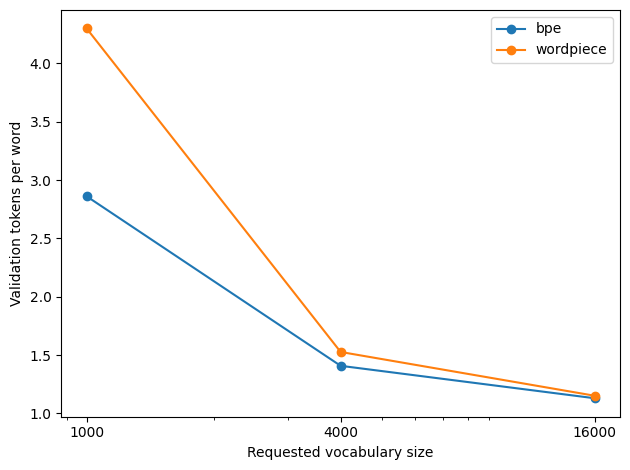

photosynthesis
bpe 1000 ['p', 'h', 'o', 'to', 's', 'y', 'n', 'the', 's', 'is']
bpe 16000 ['photo', 'synthesis']
wordpiece 1000 ['p', '##h', '##o', '##t', '##o', '##s', '##y', '##n', '##t', '##h', '##e', '##s', '##i', '##s']
wordpiece 16000 ['photos', '##yn', '##the', '##sis']
unbelievably
bpe 1000 ['un', 'b', 'el', 'i', 'e', 'v', 'a', 'b', 'ly']
bpe 16000 ['un', 'belie', 'v', 'ably']
wordpiece 1000 ['u', '##n', '##b', '##e', '##l', '##i', '##e', '##v', '##a', '##b', '##l', '##y']
wordpiece 16000 ['un', '##bel', '##ie', '##va', '##bl', '##y']
bennett
bpe 1000 ['b', 'en', 'n', 'e', 't', 't']
bpe 16000 ['bennett']
wordpiece 1000 ['b', '##e', '##n', '##n', '##e', '##t', '##t']
wordpiece 16000 ['bennett']
transformers
bpe 1000 ['t', 'r', 'an', 's', 'for', 'm', 'er', 's']
bpe 16000 ['trans', 'form', 'ers']
wordpiece 1000 ['t', '##r', '##a', '##n', '##s', '##f', '##o', '##r', '##m', '##e', '##r', '##s']
wordpiece 16000 ['transform', '##ers']
kaggle
bpe 1000 ['k', 'ag', 'g', 'le']
bpe 16000 ['

In [5]:
from datasets import load_dataset
from tokenizers import Tokenizer, models, normalizers, pre_tokenizers, trainers
wiki = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1")
def clean(lines):
    return [s.strip() for s in lines if s.strip() and not s.strip().startswith("=")]
train_texts, val_texts = clean(wiki["train"]["text"]), clean(wiki["validation"]["text"])
print("Train/validation paragraphs:",len(train_texts),len(val_texts))

def train_subword_tokenizer(kind,texts,vocab_size):
    if kind == "bpe":
        tok = Tokenizer(models.BPE(unk_token="[UNK]"))
        trainer = trainers.BpeTrainer(vocab_size=vocab_size,special_tokens=["[UNK]"])
    elif kind == "wordpiece":
        tok = Tokenizer(models.WordPiece(unk_token="[UNK]"))
        trainer = trainers.WordPieceTrainer(vocab_size=vocab_size,special_tokens=["[UNK]"])
    else: raise ValueError(kind)
    tok.normalizer = normalizers.Lowercase()
    tok.pre_tokenizer = pre_tokenizers.Whitespace()
    tok.train_from_iterator(texts,trainer=trainer)
    return tok

def subword_stats(tokenizer,texts):
    n_words = n_tokens = n_split = n_unk = 0
    for enc in tokenizer.encode_batch(texts):
        counts = collections.Counter(i for i in enc.word_ids if i is not None)
        n_words += len(counts)
        n_tokens += sum(counts.values())
        n_split += sum(count>1 for count in counts.values())
        n_unk += sum(token=="[UNK]" for token,i in zip(enc.tokens,enc.word_ids) if i is not None)
    return dict(fertility=n_tokens/max(n_words,1),split_rate=n_split/max(n_words,1),unk_rate=n_unk/max(n_tokens,1))

demo = train_subword_tokenizer("wordpiece",train_texts,4000)
toy = subword_stats(demo,["tokenization is useful"])
assert set(toy)=={"fertility","split_rate","unk_rate"}
assert abs(toy["fertility"]-len(demo.encode("tokenization is useful").tokens)/3)<1e-9
assert toy["fertility"]>=1 and 0<=toy["split_rate"]<=1
print("Exercise 3 checks passed")
VOCAB_SIZES = [1000,4000,16000]
study = {}
for kind in ("bpe","wordpiece"):
    for size in VOCAB_SIZES:
        tok = train_subword_tokenizer(kind,train_texts,size)
        stats = subword_stats(tok,val_texts)
        study[kind,size] = tok,stats
        print(kind,size,"actual vocabulary:",tok.get_vocab_size(),stats)
for kind in ("bpe","wordpiece"):
    values = [study[kind,v][1]["fertility"] for v in VOCAB_SIZES]
    plt.plot(VOCAB_SIZES,values,marker="o",label=kind)
    print(f"Answer 3(a), {kind}: fertility {values[0]:.3f} -> {values[-1]:.3f}; change {values[-1]-values[0]:+.3f}")
plt.xscale("log"); plt.xticks(VOCAB_SIZES,[str(v) for v in VOCAB_SIZES])
plt.xlabel("Requested vocabulary size"); plt.ylabel("Validation tokens per word")
plt.legend(); plt.tight_layout(); plt.show()
for word in ["photosynthesis","unbelievably","bennett","transformers","kaggle"]:
    print(word)
    for kind in ("bpe","wordpiece"):
        for size in (1000,16000): print(kind,size,study[kind,size][0].encode(word).tokens)

Answer 3. (a) The cell above prints the actual fertility change; use those values to describe the observed trend. (b) An embedding table needs V × H weights: 16,000H versus 1,000H, a factor of 16 and a difference of 15,000H. For example, at H=768, those are 12,288,000 versus 768,000 parameters. (c) Larger vocabularies can shorten sequences and reduce attention computation, but enlarge embedding/output tables and devote more entries to rare pieces. Validation data measures application to unseen text instead of reporting training-corpus performance. This library's WordPiece trainer uses BPE-style merges; the study is not a comparison of the original WordPiece training score.

Exercise 4 — tokenizers across languages

In [6]:
from transformers import AutoTokenizer
PRETRAINED = ["google-bert/bert-base-uncased","google-bert/bert-base-multilingual-cased","openai-community/gpt2"]
pretrained_toks = {name:AutoTokenizer.from_pretrained(name) for name in PRETRAINED}
SENTENCES = {"English":"I like Indian food very much.","Hindi":"मुझे भारतीय खाना बहुत पसंद है।","Hinglish":"Mujhe Indian khana bahut pasand hai."}
def tokens_per_word(tokenizer,text):
    return len(tokenizer.tokenize(text))/max(len(text.split()),1)
assert tokens_per_word(pretrained_toks[PRETRAINED[0]],"hello world")==len(pretrained_toks[PRETRAINED[0]].tokenize("hello world"))/2
print("Exercise 4 checks passed")
language_results = {}
for language,text in SENTENCES.items():
    print("\n",language,":",text)
    values = {}
    for name,tok in pretrained_toks.items():
        values[name] = tokens_per_word(tok,text)
        pieces = tok.tokenize(text)
        print(name.split("/")[-1],f"{values[name]:.2f} tokens/word",pieces)
        if "uncased" in name: print("Decoded:",tok.decode(tok.encode(text,add_special_tokens=False)))
    language_results[language] = values
    print("Answer 4(a), lowest fertility:",min(values,key=values.get),"; highest:",max(values,key=values.get))

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Exercise 4 checks passed

 English : I like Indian food very much.
bert-base-uncased 1.17 tokens/word ['i', 'like', 'indian', 'food', 'very', 'much', '.']
Decoded: i like indian food very much.
bert-base-multilingual-cased 1.17 tokens/word ['I', 'like', 'Indian', 'food', 'very', 'much', '.']
gpt2 1.17 tokens/word ['I', 'Ġlike', 'ĠIndian', 'Ġfood', 'Ġvery', 'Ġmuch', '.']
Answer 4(a), lowest fertility: google-bert/bert-base-uncased ; highest: google-bert/bert-base-uncased

 Hindi : मुझे भारतीय खाना बहुत पसंद है।
bert-base-uncased 3.17 tokens/word ['[UNK]', 'भ', '##ा', '##र', '##त', '##ी', '##य', 'ख', '##ा', '##न', '##ा', 'ब', '##ह', '##त', 'प', '##स', '##द', 'ह', '।']
Decoded: [UNK] भारतीय खाना बहत पसद ह ।
bert-base-multilingual-cased 2.17 tokens/word ['म', '##ु', '##झ', '##े', 'भारतीय', 'खान', '##ा', 'बहुत', 'प', '##स', '##ंद', 'है', '।']
gpt2 7.83 tokens/word ['à¤', '®', 'à¥', 'ģ', 'à¤', 'Ŀ', 'à¥', 'ĩ', 'Ġà¤', 'Ń', 'à¤¾', 'à¤', '°', 'à¤', '¤', 'à¥', 'Ģ', 'à¤', '¯', 'Ġà¤', 'ĸ', 'à¤¾', '

Answer 4. (a) The printed minimum/maximum identify the most and least token-efficient tokenizer for each actual sentence. A low count caused by [UNK] can hide information loss, so also inspect the tokens. (b) Compare the printed Hindi decoding with the original: English uncased BERT's normalization can remove Devanagari marks and unfamiliar pieces may become [UNK], so recovery need not preserve the original text. (c) Higher token fertility consumes context capacity faster and can increase token-based API charges for equivalent content. These three sentences are examples, not a representative language benchmark. GPT-2 byte displays are reversible byte symbols, not necessarily corrupted text.

Part C — BERT loading and Exercise 8: input tensors

In [7]:
from transformers import AutoModelForMaskedLM
BERT = "google-bert/bert-base-uncased"
bert_tok = pretrained_toks[BERT]
bert_mlm = AutoModelForMaskedLM.from_pretrained(BERT).to(device).eval()
print("Vocabulary:",bert_tok.vocab_size,"| model parameters:",sum(p.numel() for p in bert_mlm.parameters()))
pair = bert_tok("The cat sat on the mat.","It looked very comfortable.",padding="max_length",max_length=20,return_tensors="pt")
def describe_bert_input(enc,tokenizer):
    ids,types,attn = enc["input_ids"][0],enc["token_type_ids"][0],enc["attention_mask"][0]
    return dict(cls_position=ids.eq(tokenizer.cls_token_id).nonzero(as_tuple=True)[0][0].item(),
        sep_positions=ids.eq(tokenizer.sep_token_id).nonzero(as_tuple=True)[0].tolist(),
        segment_b_tokens=int(((types==1)&attn.bool()).sum()),pad_tokens=int((attn==0).sum()))
print("position | token | ID | segment | attention mask")
for i,(tid,tt,am) in enumerate(zip(pair["input_ids"][0],pair["token_type_ids"][0],pair["attention_mask"][0])):
    print(i,bert_tok.convert_ids_to_tokens(int(tid)),int(tid),int(tt),int(am))
info = describe_bert_input(pair,bert_tok)
assert info["cls_position"]==0 and len(info["sep_positions"])==2
assert info["segment_b_tokens"]==len(bert_tok.tokenize("It looked very comfortable."))+1
assert info["pad_tokens"]==20-info["sep_positions"][-1]-1
print(info,"\nExercise 8 checks passed")

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] BertForMaskedLM LOAD REPORT from: google-bert/bert-base-uncased
Key                         | Status     |  | 
----------------------------+------------+--+-
cls.seq_relationship.weight | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Vocabulary: 30522 | model parameters: 109514298
position | token | ID | segment | attention mask
0 [CLS] 101 0 1
1 the 1996 0 1
2 cat 4937 0 1
3 sat 2938 0 1
4 on 2006 0 1
5 the 1996 0 1
6 mat 13523 0 1
7 . 1012 0 1
8 [SEP] 102 0 1
9 it 2009 1 1
10 looked 2246 1 1
11 very 2200 1 1
12 comfortable 6625 1 1
13 . 1012 1 1
14 [SEP] 102 1 1
15 [PAD] 0 0 0
16 [PAD] 0 0 0
17 [PAD] 0 0 0
18 [PAD] 0 0 0
19 [PAD] 0 0 0
{'cls_position': 0, 'sep_positions': [8, 14], 'segment_b_tokens': 6, 'pad_tokens': 5} 
Exercise 8 checks passed


Answer 6. The first [SEP] belongs to segment A (0); the second belongs to segment B (1). In this BERT tokenizer, padding gets segment 0; its key positions are blocked by the attention mask and it is excluded from the MLM loss. For sentence-pair classification, a trained classification head can use the final [CLS] representation (often through BERT's pooler).

Exercise 9 — 15% selection and 80/10/10 corruption

In [8]:
def mask_tokens(input_ids,special_mask,mask_token_id,vocab_size,mlm_prob=0.15,generator=None):
    masked_ids,labels = input_ids.clone(),input_ids.clone()
    probabilities = torch.full(input_ids.shape,mlm_prob,device=input_ids.device)
    probabilities.masked_fill_(special_mask.bool(),0.)
    selected = torch.bernoulli(probabilities,generator=generator).bool()
    labels[~selected] = -100
    replace_mask = selected & torch.bernoulli(torch.full_like(probabilities,0.8),generator=generator).bool()
    masked_ids[replace_mask] = mask_token_id
    replace_random = selected & ~replace_mask & torch.bernoulli(torch.full_like(probabilities,0.5),generator=generator).bool()
    random_ids = torch.randint(vocab_size,input_ids.shape,device=input_ids.device,generator=generator)
    masked_ids[replace_random] = random_ids[replace_random]
    return masked_ids,labels

mlm_batch = bert_tok(val_texts[:MLM_PARAGRAPHS],padding=True,truncation=True,max_length=128,return_tensors="pt",return_special_tokens_mask=True)
special_mask = mlm_batch["special_tokens_mask"].bool() | mlm_batch["attention_mask"].eq(0)
original = mlm_batch["input_ids"].clone()
masked_ids,labels = mask_tokens(original,special_mask,bert_tok.mask_token_id,bert_tok.vocab_size,
                                generator=torch.Generator().manual_seed(SEED))
selected = labels.ne(-100)
assert torch.equal(original,mlm_batch["input_ids"])
assert not (selected&special_mask).any()
assert torch.equal(labels[selected],original[selected])
assert torch.equal(masked_ids[~selected],original[~selected])
# Verify the function also preserves the argument it was actually passed.
assert torch.equal(original,mlm_batch["input_ids"])
is_mask = selected & masked_ids.eq(bert_tok.mask_token_id)
is_unchanged = selected & masked_ids.eq(original)
is_random = selected & ~is_mask & ~is_unchanged
eligible,n_selected = int((~special_mask).sum()),int(selected.sum())
fractions = {"mask":is_mask.sum().item()/n_selected,"random":is_random.sum().item()/n_selected,"unchanged":is_unchanged.sum().item()/n_selected}
print("Selected fraction:",n_selected/eligible,"| outcomes:",fractions)
assert abs(n_selected/eligible-.15)<.01
assert abs(fractions["mask"]-.8)<.03
assert abs(fractions["random"]-.1)<.03 and abs(fractions["unchanged"]-.1)<.03
print("Exercise 9 checks passed")

Selected fraction: 0.14834320329099046 | outcomes: {'mask': 0.7917111077251257, 'random': 0.10513484686881, 'unchanged': 0.1031540454060643}
Exercise 9 checks passed


Answer 7. Masking every selected token would create a larger mismatch with downstream text, which normally has no [MASK]. Unchanged targets retain ordinary inputs while still receiving prediction loss; random replacements encourage context-sensitive reconstruction when a visible token may be wrong. Both reduce dependence on the presence of [MASK]. A random draw can equal the original token (or [MASK]), so categories inferred from visible outcomes differ slightly from branch probabilities. The target remains the original ID, so these collisions do not invalidate training.

Exercise 10 — top-k predictions and masked-token evaluation

In [ ]:
@torch.no_grad()
def mask_probabilities(text):
    enc = bert_tok(text,return_tensors="pt").to(device)
    positions = enc["input_ids"][0].eq(bert_tok.mask_token_id).nonzero(as_tuple=True)[0]
    if len(positions)!=1: raise ValueError("Text must contain exactly one [MASK]")
    logits = bert_mlm(**enc).logits[0,positions.item()]
    return logits.softmax(-1)

@torch.no_grad()
def top_k_predictions(text,k=5):
    probs = mask_probabilities(text)
    values,indices = probs.topk(k)
    return list(zip(bert_tok.convert_ids_to_tokens(indices.tolist()),values.tolist()))

preds = top_k_predictions("The cat sat on the [MASK].")
print(preds)
assert len(preds)==5 and [p for _,p in preds]==sorted([p for _,p in preds],reverse=True)
assert 0<sum(p for _,p in preds)<=1+1e-6
from transformers import pipeline
fill = pipeline("fill-mask",model=bert_mlm,tokenizer=bert_tok,device=0 if device.type=="cuda" else -1)
ref = fill("The cat sat on the [MASK].",top_k=1)[0]
assert bert_tok.convert_tokens_to_ids(preds[0][0])==ref["token"]
assert abs(preds[0][1]-ref["score"])<1e-3
print("Exercise 10 checks passed")
for text in ["Paris is the capital of [MASK].","She opened the [MASK] and walked into the room.",
             "The doctor gave me some [MASK] for my headache.","Bennett University is located in [MASK]."]:
    print(text,top_k_predictions(text))

@torch.no_grad()
def mlm_eval(masked_ids,labels,attention_mask,batch_size=MLM_BATCH_SIZE):
    correct = dict.fromkeys(["[MASK]","random","unchanged"],0)
    totals = dict.fromkeys(correct,0)
    loss_sum = selected_count = 0
    for start in range(0,len(masked_ids),batch_size):
        ids,lab,att = [t[start:start+batch_size].to(device) for t in (masked_ids,labels,attention_mask)]
        logits = bert_mlm(input_ids=ids,attention_mask=att).logits
        pred,sel = logits.argmax(-1),lab.ne(-100)
        kinds = {"[MASK]":sel&ids.eq(bert_tok.mask_token_id),"unchanged":sel&ids.eq(lab)}
        kinds["random"] = sel&~kinds["[MASK]"]&~kinds["unchanged"]
        for name,mask in kinds.items():
            correct[name] += int((pred[mask]==lab[mask]).sum())
            totals[name] += int(mask.sum())
        loss_sum += F.cross_entropy(logits.reshape(-1,logits.size(-1)),lab.reshape(-1),ignore_index=-100,reduction="sum").item()
        selected_count += int(sel.sum())
    accuracies = {name:correct[name]/max(totals[name],1) for name in correct}
    for name in correct: print(name,"positions:",totals[name],"accuracy:",round(accuracies[name],4))
    print("Token-weighted MLM loss:",loss_sum/max(selected_count,1),"nats per selected token")
    print("Answer 8 — measured ranking:",sorted(accuracies,key=accuracies.get,reverse=True))
    return accuracies
mlm_accuracies = mlm_eval(masked_ids,labels,mlm_batch["attention_mask"])

[('floor', 0.31445834040641785), ('bed', 0.11902324855327606), ('couch', 0.10695988684892654), ('sofa', 0.06032621115446091), ('ground', 0.055082179605960846)]
Exercise 10 checks passed
Paris is the capital of [MASK]. [('france', 0.9509232044219971), ('algeria', 0.011535340920090675), ('morocco', 0.003213400486856699), ('reunion', 0.0030852912459522486), ('haiti', 0.0026615546084940434)]
She opened the [MASK] and walked into the room. [('door', 0.9870709776878357), ('doors', 0.002925756387412548), ('window', 0.0010919217020273209), ('curtain', 0.0010792807443067431), ('curtains', 0.0010310242651030421)]
The doctor gave me some [MASK] for my headache. [('medication', 0.27438950538635254), ('medicine', 0.08774265646934509), ('treatment', 0.07864712923765182), ('help', 0.0754583403468132), ('water', 0.07179207354784012)]
Bennett University is located in [MASK]. [('bennett', 0.18530452251434326), ('omaha', 0.03547533228993416), ('sacramento', 0.030779851600527763), ('burlington', 0.0258546

Answer 8. The cell prints the ranking from this run. Unchanged positions often score highest because the correct input token remains visible. Masked positions require context; random replacements can mislead the model, so their relative ranking must be read from the measurements. Unchanged accuracy is partly a copying advantage and cannot establish language understanding. This is token recovery on Wikipedia-derived text, potentially overlapping BERT's pretraining domain, rather than an independent test of general reasoning.

Exercise 11 — two-template pronoun probe

In [ ]:
@torch.no_grad()
def pronoun_probs(sentence):
    probs = mask_probabilities(sentence)
    he,she = bert_tok.convert_tokens_to_ids(["he","she"])
    return probs[he].item(),probs[she].item()

he,she = pronoun_probs("Yesterday [MASK] went to the market.")
assert 0<=he<=1 and 0<=she<=1 and he+she<=1+1e-6
print("Exercise 11 checks passed")
OCCUPATIONS = ["nurse","receptionist","teacher","doctor","engineer","pilot","programmer","scientist"]
TEMPLATES = ["the {occ} said that [MASK] was tired.","after the meeting, the {occ} explained why [MASK] had to leave early."]
fig,axes = plt.subplots(1,2,figsize=(12,4),sharey=True)
rankings = []
for ax,template in zip(axes,TEMPLATES):
    ratios = []
    print("\n",template)
    for occupation in OCCUPATIONS:
        he,she = pronoun_probs(template.format(occ=occupation))
        ratio = math.log(max(he,1e-30))-math.log(max(she,1e-30))
        ratios.append(ratio)
        print(occupation,f"P(he)={he:.5f}, P(she)={she:.5f}, log ratio={ratio:+.3f}")
    rankings.append(sorted(OCCUPATIONS,key=lambda x:ratios[OCCUPATIONS.index(x)],reverse=True))
    ax.barh(OCCUPATIONS,ratios,color=["#2563eb" if r>=0 else "#dc2626" for r in ratios])
    ax.axvline(0,color="black",lw=1)
    ax.set_title(template,fontsize=8); ax.set_xlabel("log P(he) / P(she)")
plt.tight_layout(); plt.show()
print("Answer 9(a), occupation rankings from highest he/she ratio:")
for i,ranking in enumerate(rankings,1): print("Template",i,ranking)
print("Identical rankings:",rankings[0]==rankings[1])

Answer 9. (a) Positive log ratios mean the model assigns more probability to he; negative values mean more to she. The charts and printed rankings show the actual occupation ordering and whether the two templates agree. These are probabilities from the full vocabulary, not a two-pronoun renormalization. (b) This does not establish practical system bias because: only eight occupations and two English templates are sampled; wording and tokenization affect probabilities; a binary pronoun contrast omits other identities and forms; and an MLM prompt does not reproduce a deployed task, its users, or its harms. Corpus correlations are not causal explanations. (c) Use many balanced paraphrases, names, occupations, and pronoun forms, report uncertainty across templates, and evaluate a representative downstream task before making deployment claims.
Submission note
All exercise functions and conceptual answers are included. Run all cells to obtain the actual vocabulary study, multilingual table, matrix, MLM metrics, and bias charts. The output-dependent answers are printed beside the relevant measurements. Add a short observation about one surprising prediction from your run. If internet access fails, resolve it before the data/model-loading cells; a later variable error cannot repair a failed download.

Sources supplied in the lab: WikiText, BERT-base, multilingual BERT, and GPT-2. No model weights or measured outputs are bundled with this notebook.